[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_1_do_problema_a_decisao/02_Da_Pergunta_ao_Enquadramento.ipynb)

# Capítulo 2 – Da pergunta ao enquadramento

Um projeto de ciência de dados começa por uma pergunta, e o tipo de pergunta decide quase tudo o que vem a seguir: que dados servem, que análise faz sentido e como se avalia o resultado. Este capítulo apresenta os quatro tipos de pergunta, aplica cada um aos mesmos dados e mostra como se passa de uma preocupação vaga a uma pergunta que apoia uma decisão.

> **Objetivos:** distinguir perguntas descritivas, explicativas, preditivas e de decisão; reconhecer porque uma associação não prova uma causa; identificar fugas de informação numa previsão; enquadrar um problema com cinco perguntas; reescrever uma preocupação vaga como pergunta de decisão.

**Pré-requisitos:** capítulo 1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_consultas(n=10_000, semente=42):
    """Gera marcações de consultas de uma clínica fictícia (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    antecedencia = rng.gamma(2.0, 9.0, n).round().clip(0, 90).astype(int)
    idade = rng.integers(18, 90, n)
    faltas_anteriores = rng.poisson(0.4, n)
    dia = rng.choice(["seg", "ter", "qua", "qui", "sex"], n)
    # A clínica envia mais lembretes por SMS a quem já faltou antes
    lembrete = rng.random(n) < 0.05 + 0.70 * (faltas_anteriores >= 1)
    z = (-3.7 + 0.05 * antecedencia + 1.0 * faltas_anteriores
         - 0.012 * (idade - 18) - 0.6 * lembrete + 0.3 * (dia == "seg"))
    faltou = rng.random(n) < 1 / (1 + np.exp(-z))
    return pd.DataFrame({"antecedencia_dias": antecedencia, "idade": idade,
                         "faltas_anteriores": faltas_anteriores, "dia_semana": dia,
                         "lembrete": lembrete, "faltou": faltou})


consultas = gerar_consultas()
consultas.head()

,antecedencia_dias,idade,faltas_anteriores,dia_semana,lembrete,faltou
0,19,55,2,qua,True,False
1,26,42,2,sex,True,False
2,17,48,0,ter,False,False
3,15,34,1,ter,False,False
4,28,43,0,sex,False,False


## Quatro tipos de pergunta

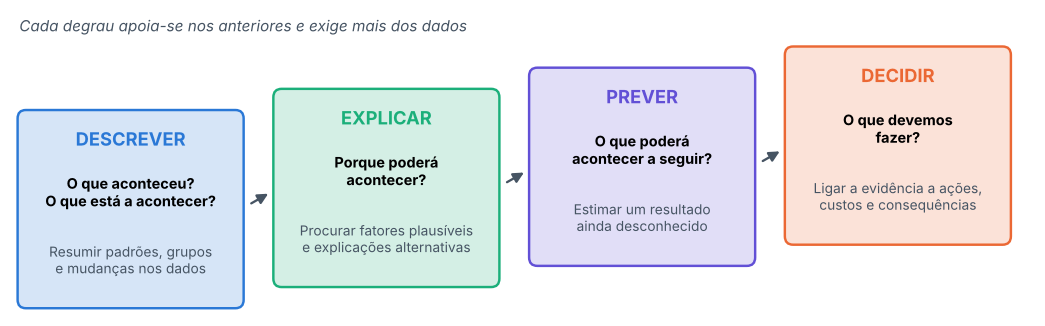

In [3]:
tipos = [("DESCREVER", "O que aconteceu?\nO que está a acontecer?", "Resumir padrões, grupos\ne mudanças nos dados", AZUL),
         ("EXPLICAR", "Porque poderá\nacontecer?", "Procurar fatores plausíveis\ne explicações alternativas", VERDE),
         ("PREVER", "O que poderá\nacontecer a seguir?", "Estimar um resultado\nainda desconhecido", VIOLETA),
         ("DECIDIR", "O que devemos\nfazer?", "Ligar a evidência a ações,\ncustos e consequências", LARANJA)]

fig, ax = tela(12.4, 3.6, (12, 3.6))
for i, (nome, pergunta, descricao, cor) in enumerate(tipos):
    x = 0.1 + i * 3.1
    caixa(ax, x, 0.1 + i * 0.25, 2.7, 2.3, "", cor)
    ax.text(x + 1.35, 2.0 + i * 0.25, nome, ha="center", fontweight="bold", color=cor, fontsize=12)
    ax.text(x + 1.35, 1.45 + i * 0.25, pergunta, ha="center", va="center", fontweight="bold", fontsize=9.5)
    ax.text(x + 1.35, 0.65 + i * 0.25, descricao, ha="center", va="center", fontsize=9, color="#465463")
    if i < 3:
        seta(ax, (x + 2.78, 1.3 + i * 0.25), (x + 3.05, 1.45 + i * 0.25))
ax.text(0.1, 3.35, "Cada degrau apoia-se nos anteriores e exige mais dos dados", style="italic", color="#465463")
plt.show()

Os quatro tipos formam uma escada. Não se consegue explicar sem primeiro descrever, e uma boa decisão costuma precisar de uma previsão. Mas subir a escada não é obrigatório: muitas vezes uma boa descrição resolve o problema.

Vamos fazer as quatro perguntas aos mesmos dados.

## Descrever: o que aconteceu?

Descrever é resumir. Não se afirma nada sobre causas nem sobre o futuro.

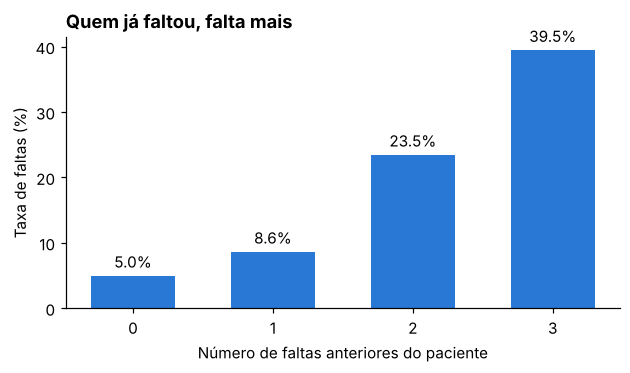

In [4]:
resumo = consultas.groupby("faltas_anteriores")["faltou"].agg(taxa="mean", marcacoes="size")
resumo = resumo[resumo["marcacoes"] >= 50]

fig, ax = plt.subplots(figsize=(6.5, 3.2))
barras = ax.bar(resumo.index.astype(str), resumo["taxa"] * 100, color=AZUL, width=0.6)
ax.bar_label(barras, fmt="%.1f%%", padding=3)
ax.set_xlabel("Número de faltas anteriores do paciente")
ax.set_ylabel("Taxa de faltas (%)")
ax.set_title("Quem já faltou, falta mais")
plt.show()

## Explicar: porque poderá acontecer?

A clínica envia lembretes por SMS e quer saber se funcionam. A comparação óbvia é entre quem recebeu lembrete e quem não recebeu.

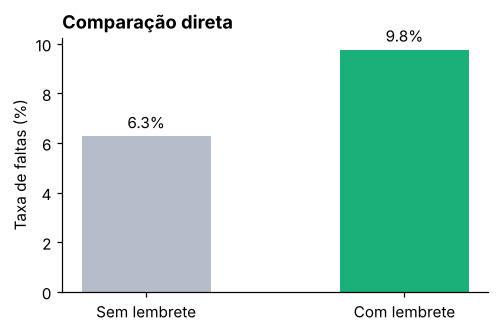

In [5]:
simples = consultas.groupby("lembrete")["faltou"].mean() * 100

fig, ax = plt.subplots(figsize=(5, 3))
barras = ax.bar(["Sem lembrete", "Com lembrete"], simples, color=[CINZA, VERDE], width=0.5)
ax.bar_label(barras, fmt="%.1f%%", padding=3)
ax.set_ylabel("Taxa de faltas (%)")
ax.set_title("Comparação direta")
plt.show()

Quem recebeu lembrete faltou **mais**. Conclusão apressada: os lembretes são contraproducentes e devem acabar.

Antes de aceitar esta conclusão, um cientista de dados pergunta: **quem é que recebe lembretes?** A clínica não os envia ao acaso. Envia-os sobretudo a quem já faltou antes, e esses pacientes faltam mais por natureza. Os dois grupos não são comparáveis.

A comparação justa faz-se entre pacientes parecidos.

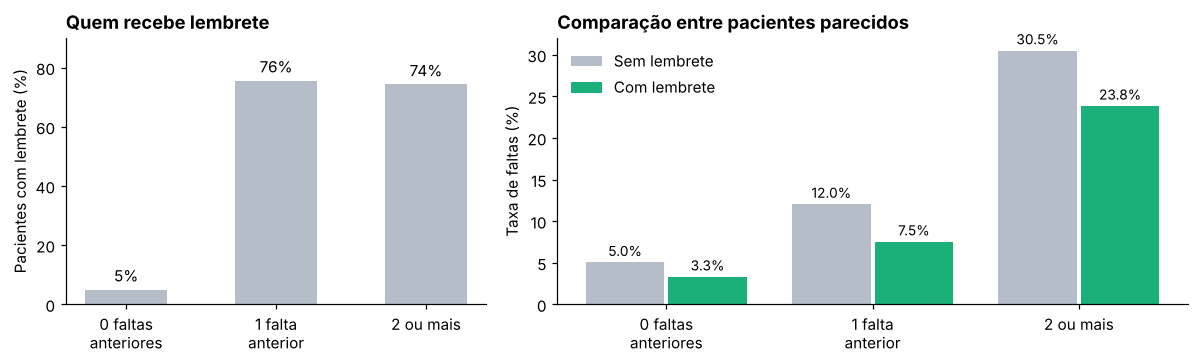

In [6]:
historico = consultas["faltas_anteriores"].clip(upper=2).map({0: "0 faltas\nanteriores", 1: "1 falta\nanterior", 2: "2 ou mais"})
justa = consultas.groupby([historico, "lembrete"])["faltou"].mean().unstack() * 100
envio = consultas.groupby(historico)["lembrete"].mean() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 1.5]})
barras = ax1.bar(envio.index, envio, color=CINZA, width=0.55)
ax1.bar_label(barras, fmt="%.0f%%", padding=3)
ax1.set_title("Quem recebe lembrete")
ax1.set_ylim(0, 90)
ax1.set_ylabel("Pacientes com lembrete (%)")

x = np.arange(3)
b1 = ax2.bar(x - 0.2, justa[False], 0.38, color=CINZA, label="Sem lembrete")
b2 = ax2.bar(x + 0.2, justa[True], 0.38, color=VERDE, label="Com lembrete")
ax2.bar_label(b1, fmt="%.1f%%", padding=2, fontsize=9)
ax2.bar_label(b2, fmt="%.1f%%", padding=2, fontsize=9)
ax2.set_xticks(x, justa.index)
ax2.set_ylabel("Taxa de faltas (%)")
ax2.set_title("Comparação entre pacientes parecidos")
ax2.legend(frameon=False)
plt.tight_layout()
plt.show()

Dentro de cada grupo, quem recebeu lembrete faltou **menos**. A comparação direta dizia o contrário porque misturava dois efeitos: o do lembrete e o do historial do paciente. A uma variável que influencia ao mesmo tempo a «causa» e o «efeito» chama-se **variável de confusão**, e a inversão que acabámos de ver é conhecida por paradoxo de Simpson.

> **Associação não é causalidade.** Dois valores que andam juntos podem ter uma causa comum, a relação pode ser a inversa da que parece, ou pode ser coincidência. Uma explicação só merece confiança depois de se procurarem as explicações alternativas.

Mesmo a segunda comparação não prova que o lembrete *causa* a redução: pode haver outras diferenças entre os grupos que não medimos. A forma mais segura de saber é uma **experiência**: sortear quem recebe o lembrete e comparar os dois grupos.

## Prever: o que poderá acontecer?

Prever é estimar um valor que ainda não conhecemos. Um modelo de previsão pode ser muito simples. O que se segue atribui pontos de risco a cada marcação.

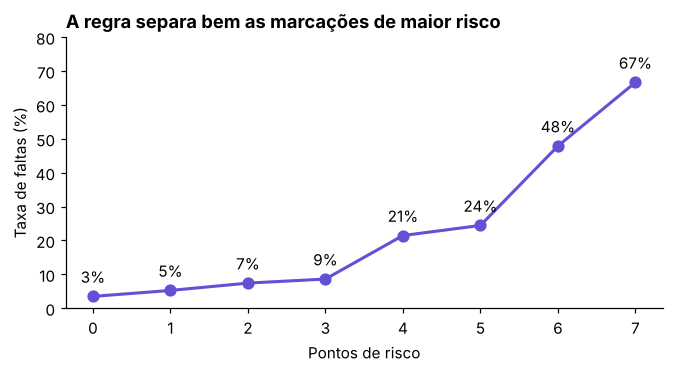

In [7]:
def pontos_de_risco(marcacoes):
    """Regra simples: mais antecedência e mais faltas anteriores dão mais risco."""
    return (marcacoes["antecedencia_dias"] > 30) * 2 + marcacoes["faltas_anteriores"].clip(upper=2) * 2 \
        + (marcacoes["dia_semana"] == "seg") * 1


consultas["risco"] = pontos_de_risco(consultas)
por_risco = consultas.groupby("risco")["faltou"].agg(taxa="mean", marcacoes="size")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(por_risco.index, por_risco["taxa"] * 100, color=VIOLETA, lw=2, marker="o", ms=7)
for r, linha in por_risco.iterrows():
    ax.annotate(f"{linha['taxa']:.0%}", (r, linha["taxa"] * 100), textcoords="offset points", xytext=(0, 9), ha="center")
ax.set_xlabel("Pontos de risco")
ax.set_ylabel("Taxa de faltas (%)")
ax.set_title("A regra separa bem as marcações de maior risco")
ax.set_ylim(0, por_risco["taxa"].max() * 120)
plt.show()

A regra funciona: quanto mais pontos, mais faltas. O capítulo 3 substitui-a por um modelo estatístico e mostra como avaliar previsões.

### Só se pode usar o que se sabe no momento da previsão

A previsão tem de ser feita **na véspera** da consulta. Nesse momento sabemos a antecedência, a idade, o historial e o dia. Não sabemos, por exemplo:

- a que horas o paciente chegou;
- se pagou a consulta;
- se a ficha clínica foi atualizada nesse dia.

Estas três variáveis estariam na base de dados e «preveem» a falta quase na perfeição, mas só existem **depois** do facto. Usá-las para treinar um modelo chama-se **fuga de informação** (*data leakage*). O modelo parece excelente nos testes e é inútil na prática.

> **Regra:** para cada variável, pergunta «vou conhecer este valor no momento em que tiver de fazer a previsão?». Se a resposta for não, a variável fica de fora.

## Decidir: o que devemos fazer?

A previsão ainda não é uma decisão. Suponhamos que a receção consegue fazer **300 chamadas** de confirmação por cada dez mil marcações. A quem telefona?

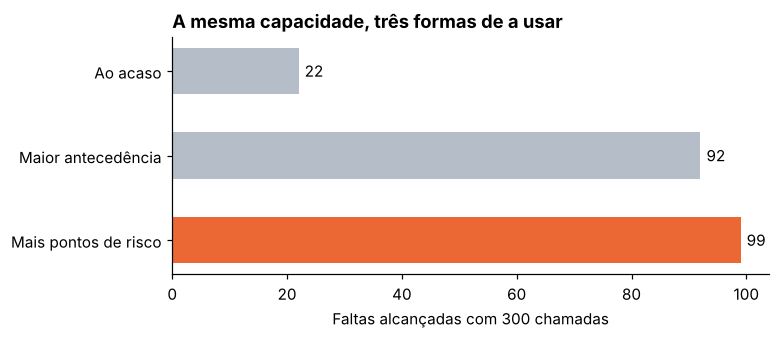

In [8]:
capacidade = 300
rng = np.random.default_rng(1)

ao_acaso = consultas.sample(capacidade, random_state=1)["faltou"].sum()
por_antecedencia = consultas.nlargest(capacidade, "antecedencia_dias")["faltou"].sum()
ordenado = consultas.assign(desempate=rng.random(len(consultas))).sort_values(["risco", "desempate"], ascending=False)
por_pontos = ordenado.head(capacidade)["faltou"].sum()

opcoes = pd.Series({"Ao acaso": ao_acaso, "Maior antecedência": por_antecedencia, "Mais pontos de risco": por_pontos})
fig, ax = plt.subplots(figsize=(7, 2.8))
barras = ax.barh(opcoes.index, opcoes, color=[CINZA, CINZA, LARANJA], height=0.55)
ax.bar_label(barras, padding=4)
ax.invert_yaxis()
ax.set_xlabel(f"Faltas alcançadas com {capacidade} chamadas")
ax.set_title("A mesma capacidade, três formas de a usar")
plt.show()

Com as mesmas 300 chamadas, a regra dos pontos alcança várias vezes mais pacientes que iam faltar do que telefonar ao acaso. É este o valor da previsão: **permite usar melhor um recurso limitado**.

Repara no que a pergunta de decisão acrescentou e que as anteriores não tinham: uma **restrição** (300 chamadas), uma **ação** (telefonar) e uma forma de comparar **alternativas**.

## Enquadrar o problema

«Temos dados» não é um problema. Há um problema de ciência de dados quando se quer:

- compreender um fenómeno;
- responder a uma pergunta;
- fazer uma previsão;
- avaliar uma intervenção;
- apoiar uma decisão.

> **Um bom projeto começa por uma pergunta que importa, não por um conjunto de dados interessante.**

### Cinco perguntas antes de abrir os dados

| N.º | Pergunta | No caso da clínica |
| --- | --- | --- |
| 1 | Qual é o problema? | Vagas vazias por faltas, com custo para a clínica e espera para outros pacientes. |
| 2 | Que decisão queremos tomar ou melhorar? | A quem telefonar na véspera. |
| 3 | Como seria uma resposta útil? | Uma lista diária, ordenada, com tantos nomes quantas as chamadas possíveis. |
| 4 | Quem vai usar a resposta? | A receção, todas as manhãs. |
| 5 | O que acontece se errarmos? | Uma chamada desnecessária custa dois minutos; uma falta não prevista custa uma vaga. |

A resposta à pergunta 5 raramente é simétrica, e isso muda a forma de avaliar o modelo. É o tema do capítulo 3.

### Da preocupação vaga à pergunta de decisão

A primeira formulação de um problema é quase sempre vaga. Enquadrar é descer estes degraus:

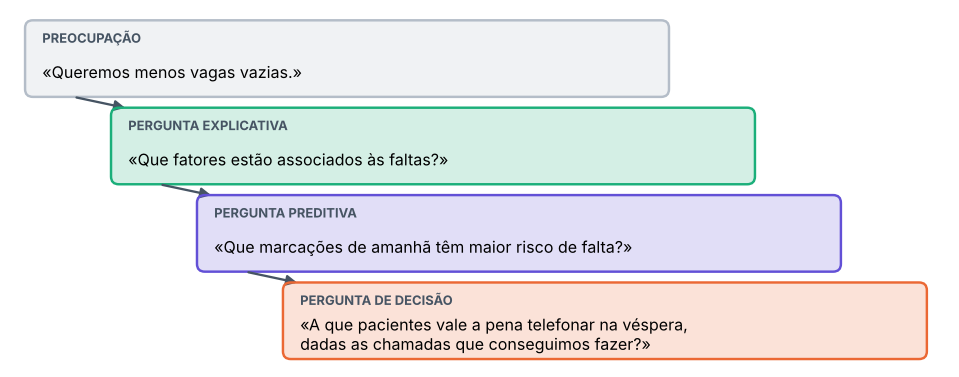

In [9]:
degraus = [("PREOCUPAÇÃO", "«Queremos menos vagas vazias.»", CINZA),
           ("PERGUNTA EXPLICATIVA", "«Que fatores estão associados às faltas?»", VERDE),
           ("PERGUNTA PREDITIVA", "«Que marcações de amanhã têm maior risco de falta?»", VIOLETA),
           ("PERGUNTA DE DECISÃO", "«A que pacientes vale a pena telefonar na véspera,\ndadas as chamadas que conseguimos fazer?»", LARANJA)]

fig, ax = tela(12, 4.6, (11, 4.2))
for i, (rotulo, texto, cor) in enumerate(degraus):
    x, y = 0.2 + i * 1.1, 3.5 - i * 1.13
    caixa(ax, x, y, 8.2, 0.95, "", cor)
    ax.text(x + 0.2, y + 0.68, rotulo, fontsize=8.5, fontweight="bold", color="#465463")
    ax.text(x + 0.2, y + 0.3, texto, fontsize=10.5, va="center")
    if i < 3:
        seta(ax, (x + 0.6, y - 0.02), (x + 1.3, y - 0.17))
plt.show()

Prever as faltas não é o objetivo. O objetivo é ter menos vagas vazias, e a previsão só interessa na medida em que ajuda a decidir a quem telefonar.

### Da previsão à ação

Uma previsão só se torna útil quando está ligada a uma decisão. A cadeia completa tem cinco elos, e cada um tem a sua pergunta.

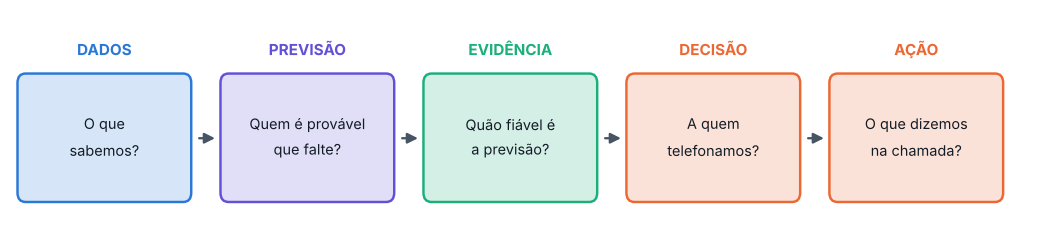

In [10]:
elos = [("DADOS", "O que\nsabemos?", AZUL), ("PREVISÃO", "Quem é provável\nque falte?", VIOLETA),
        ("EVIDÊNCIA", "Quão fiável é\na previsão?", VERDE), ("DECISÃO", "A quem\ntelefonamos?", LARANJA),
        ("AÇÃO", "O que dizemos\nna chamada?", LARANJA)]

fig, ax = tela(12.6, 2.2, (12, 2.4))
for i, (nome, pergunta, cor) in enumerate(elos):
    x = 0.1 + i * 2.5
    caixa(ax, x, 0.15, 2.1, 1.35, pergunta, cor, 9.5)
    ax.text(x + 1.05, 1.72, nome, ha="center", fontweight="bold", color=cor)
    if i < 4:
        seta(ax, (x + 2.18, 0.82), (x + 2.45, 0.82))
plt.show()

Em cada elo vale a pena perguntar: **e se isto falhar?** Se os dados estiverem incompletos, se a previsão errar, se a decisão escolher as pessoas erradas, se a chamada não mudar nada. Uma cadeia destas é tão forte como o seu elo mais fraco.

## Exercícios

### `Exercício 1` – Que tipo de pergunta é?

Classifica cada pergunta como descritiva, explicativa, preditiva ou de decisão:

1. Quantas refeições sobraram por dia na cantina no último trimestre?
2. Quantos passageiros vai ter a linha 12 na próxima segunda-feira às 8h?
3. Porque sobe o consumo de eletricidade à sexta-feira?
4. Que edifícios devem receber primeiro o novo sistema de climatização?
5. Que grupos de clientes existem na nossa base?
6. Quantas refeições devemos preparar amanhã?
7. Que máquinas vão avariar no próximo mês?
8. Os clientes com cartão de fidelização gastam mais por causa do cartão?

<details>
<summary><b>Ver uma solução possível</b></summary>

1. **Descritiva**: resume o que aconteceu.
2. **Preditiva**: estima um valor ainda desconhecido.
3. **Explicativa**: procura fatores.
4. **De decisão**: pede uma ação, com prioridades.
5. **Descritiva**: agrupar é resumir padrões.
6. **De decisão**: usa uma previsão da procura, mas a pergunta é o que fazer.
7. **Preditiva**.
8. **Explicativa**, e do tipo mais difícil: pergunta por uma causa. Os clientes que pedem o cartão podem ser, à partida, os que já gastavam mais.

</details>

### `Exercício 2` – Encontrar a variável de confusão

Um ginásio observa que os sócios que contratam um treinador pessoal cancelam a inscrição com menos frequência. A direção quer oferecer um mês de treinador a todos os sócios novos. Que explicação alternativa deves verificar primeiro, e como?

<details>
<summary><b>Ver uma solução possível</b></summary>

Quem contrata um treinador pode ser quem já estava mais motivado ou quem já frequentava mais o ginásio. A motivação influencia as duas coisas (contratar treinador e não cancelar), por isso é uma variável de confusão.

Como verificar: comparar sócios com frequência semelhante antes da contratação, com e sem treinador. Melhor ainda: oferecer o mês de treinador a um grupo de sócios novos escolhido por sorteio e comparar com os restantes.

</details>

### `Exercício 3` – Fuga de informação

Queres prever, no momento da marcação, se um paciente vai faltar. Quais destas variáveis podes usar?

`idade` · `antecedencia_dias` · `hora_de_chegada` · `faltas_anteriores` · `valor_pago` · `dia_semana` · `duracao_da_consulta`

<details>
<summary><b>Ver uma solução possível</b></summary>

Podes usar `idade`, `antecedencia_dias`, `faltas_anteriores` e `dia_semana`: todas se conhecem no momento da marcação.

Não podes usar `hora_de_chegada`, `valor_pago` nem `duracao_da_consulta`: só existem depois de a consulta acontecer (ou não). Um modelo treinado com elas teria resultados excelentes nos testes e nenhuma utilidade.

</details>

### `Exercício 4` – Experimentar outra regra

Altera a função `pontos_de_risco` (por exemplo, dando mais peso à antecedência ou usando a idade) e verifica se alcanças mais faltas com as mesmas 300 chamadas.

In [11]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
def outra_regra(marcacoes):
    return (marcacoes["antecedencia_dias"] / 10 + marcacoes["faltas_anteriores"] * 2
            - (marcacoes["idade"] - 18) / 30 + (marcacoes["dia_semana"] == "seg"))


consultas["risco2"] = outra_regra(consultas)
print(consultas.nlargest(300, "risco2")["faltou"].sum())
```

Uma regra com pesos contínuos costuma alcançar mais faltas do que a regra por pontos. Atenção: se afinares os pesos até obteres o melhor resultado nestes dados, estás a ajustar a regra a este conjunto em particular. Para saber se funciona de facto, é preciso testá-la em dados que não usaste para a afinar (capítulo 3).

</details>

## Verifica o que aprendeste

- [ ] Sei distinguir os quatro tipos de pergunta e dar um exemplo de cada.
- [ ] Sei explicar, com um exemplo, porque uma associação não prova uma causa.
- [ ] Sei o que é uma variável de confusão.
- [ ] Sei o que é uma fuga de informação e como a evitar.
- [ ] Sei as cinco perguntas a fazer antes de abrir os dados.
- [ ] Sei transformar uma preocupação vaga numa pergunta de decisão.

## Leitura recomendada

- https://en.wikipedia.org/wiki/Simpson%27s_paradox
- https://en.wikipedia.org/wiki/Confounding
- https://scikit-learn.org/stable/common_pitfalls.html